# Did Tehran Stock Exchange stocks beat inflation? (Mehr 1402 to Shahrivar 1405)

**Data:** monthly panel `data/processed/prices_monthly.parquet`. It has 36 monthly returns from
1402-07 to 1405-06, base month 1402-06. Prices are adjusted official closing prices from
TSETMC via algotik-tse. Inflation is the CPI of the Statistical Centre of Iran (all households,
whole country, 1400 = 100). *Real* always means deflated by that CPI:
real return = (1 + nominal) / (1 + inflation) - 1.

**How to read this notebook**

* **Conclusions about "the market" come only from شاخص کل (overall index, TEDPIX) and the
  equal-weight index.**
* The 8 stocks (one per sector) **illustrate dispersion across sectors; they are not the
  market.** They were picked after the fact, so any average of them is hindsight-selected.
* Stocks are **not compared with sector indices**. It is unknown whether TSETMC sector indices
  include dividends, while the adjusted stock prices do. Sector indices appear only as trend
  lines in the Power BI export, labelled "trend only".
* All code lives in `src/analysis.py`; this notebook only calls it. Tests: `tests/test_analysis.py`.

**Units.** Every return carries its unit in its name or label:
`per month` (one monthly return), `per year` (CAGR, or one 12-month block),
`cum_3y` / "cumulative over 3 years" (1402-06 to 1405-06, not annualized). Closure figures are
cumulative over the stated window.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import pandas as pd
from IPython.display import Image, Markdown, display
import analysis as an

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
res = an.run_all()          # computes all tables, writes figures and Power BI CSVs
FIG = an.FIG

def pct(df, cols, digits=1):
    out = df.copy()
    for c in cols:
        out[c] = out[c].map(lambda v: "" if pd.isna(v) else f"{v:+.{digits}%}")
    return out

## 1. Return and risk

* `nominal_cagr`, `real_cagr`: per year (CAGR over the 36 months).
* `real_cum_3y`: real return, cumulative over 3 years (1402-06 to 1405-06).
* `real_vol_per_year`: standard deviation of monthly real returns × √12, per year.
* `real_max_drawdown_peak_to_trough`: largest fall of the real cumulative index from a peak.
* `real_worst_month_per_month`, `real_best_month_per_month`: single-month real returns.
* `real_cagr_per_unit_vol` ("real return per unit of risk"): real CAGR per year divided by real
  volatility per year. It is *not* a Sharpe ratio, because there is no risk-free rate in it.

`flagged months` counts months with a market closure, a long suspension (5 or more
open-market days) or no trade. Returns in those months are less reliable.

In [2]:
rt = res["risk"]
show = rt[["series", "type", "nominal_cagr", "real_cagr", "real_cum_3y", "real_vol_per_year",
           "real_max_drawdown_peak_to_trough", "dd_peak", "dd_trough", "dd_recovery",
           "pct_months_beat_inflation", "real_worst_month_per_month", "worst_month", "real_best_month_per_month",
           "best_month", "real_cagr_per_unit_vol", "flagged_months"]]
show = pct(show, ["nominal_cagr", "real_cagr", "real_cum_3y", "real_max_drawdown_peak_to_trough",
                  "real_worst_month_per_month", "real_best_month_per_month"])
show["real_vol_per_year"] = rt["real_vol_per_year"].map(lambda v: f"{v:.1%}")
show["pct_months_beat_inflation"] = rt["pct_months_beat_inflation"].map(
    lambda v: "" if pd.isna(v) else f"{v:.0%}")
show["real_cagr_per_unit_vol"] = rt["real_cagr_per_unit_vol"].map(
    lambda v: "" if pd.isna(v) else f"{v:+.2f}")
show.fillna("")

,series,type,nominal_cagr,real_cagr,real_cum_3y,real_vol_per_year,real_max_drawdown_peak_to_trough,dd_peak,dd_trough,dd_recovery,pct_months_beat_inflation,real_worst_month_per_month,worst_month,real_best_month_per_month,best_month,real_cagr_per_unit_vol,flagged_months
0,Foolad,stock,+20.1%,-21.8%,-52.2%,41.6%,-63.4%,1402-09,1405-05,,31%,-26.7%,1404-05,+23.5%,1405-06,-0.52,12
1,Fameli,stock,+107.6%,+35.2%,+147.2%,51.7%,-32.2%,1404-10,1405-02,1405-05,47%,-21.2%,1404-11,+46.5%,1405-03,+0.68,12
2,Shepna,stock,+74.5%,+13.6%,+46.8%,58.6%,-48.5%,1402-06,1403-07,1404-10,42%,-28.0%,1404-11,+66.5%,1405-03,+0.23,8
3,Khodro,stock,+23.5%,-19.5%,-47.9%,53.3%,-59.3%,1404-02,1405-02,,36%,-34.8%,1404-05,+31.8%,1403-08,-0.37,12
4,Vbmellat,stock,+50.8%,-1.8%,-5.2%,51.2%,-50.6%,1404-01,1405-02,,39%,-21.6%,1404-11,+35.6%,1403-09,-0.03,10
5,Akhaber,stock,+24.6%,-18.8%,-46.5%,59.8%,-76.8%,1402-09,1405-02,,36%,-29.6%,1404-05,+47.2%,1405-05,-0.31,10
6,Shasta,stock,+61.2%,+5.0%,+15.8%,45.7%,-43.7%,1402-09,1405-02,1405-06,47%,-20.5%,1404-11,+30.9%,1405-03,+0.11,8
7,Tipico,stock,+52.5%,-0.7%,-2.0%,53.4%,-49.6%,1402-06,1405-02,1405-05,33%,-22.0%,1404-11,+64.9%,1405-03,-0.01,9
8,Overall index (TEDPIX),market_index,+50.1%,-2.3%,-6.6%,36.6%,-42.3%,1402-06,1405-02,,39%,-22.3%,1404-11,+28.6%,1405-03,-0.06,8
9,Equal-weight index,market_index,+38.6%,-9.7%,-26.4%,34.3%,-56.3%,1402-06,1405-02,,39%,-19.9%,1404-11,+30.8%,1405-03,-0.28,8


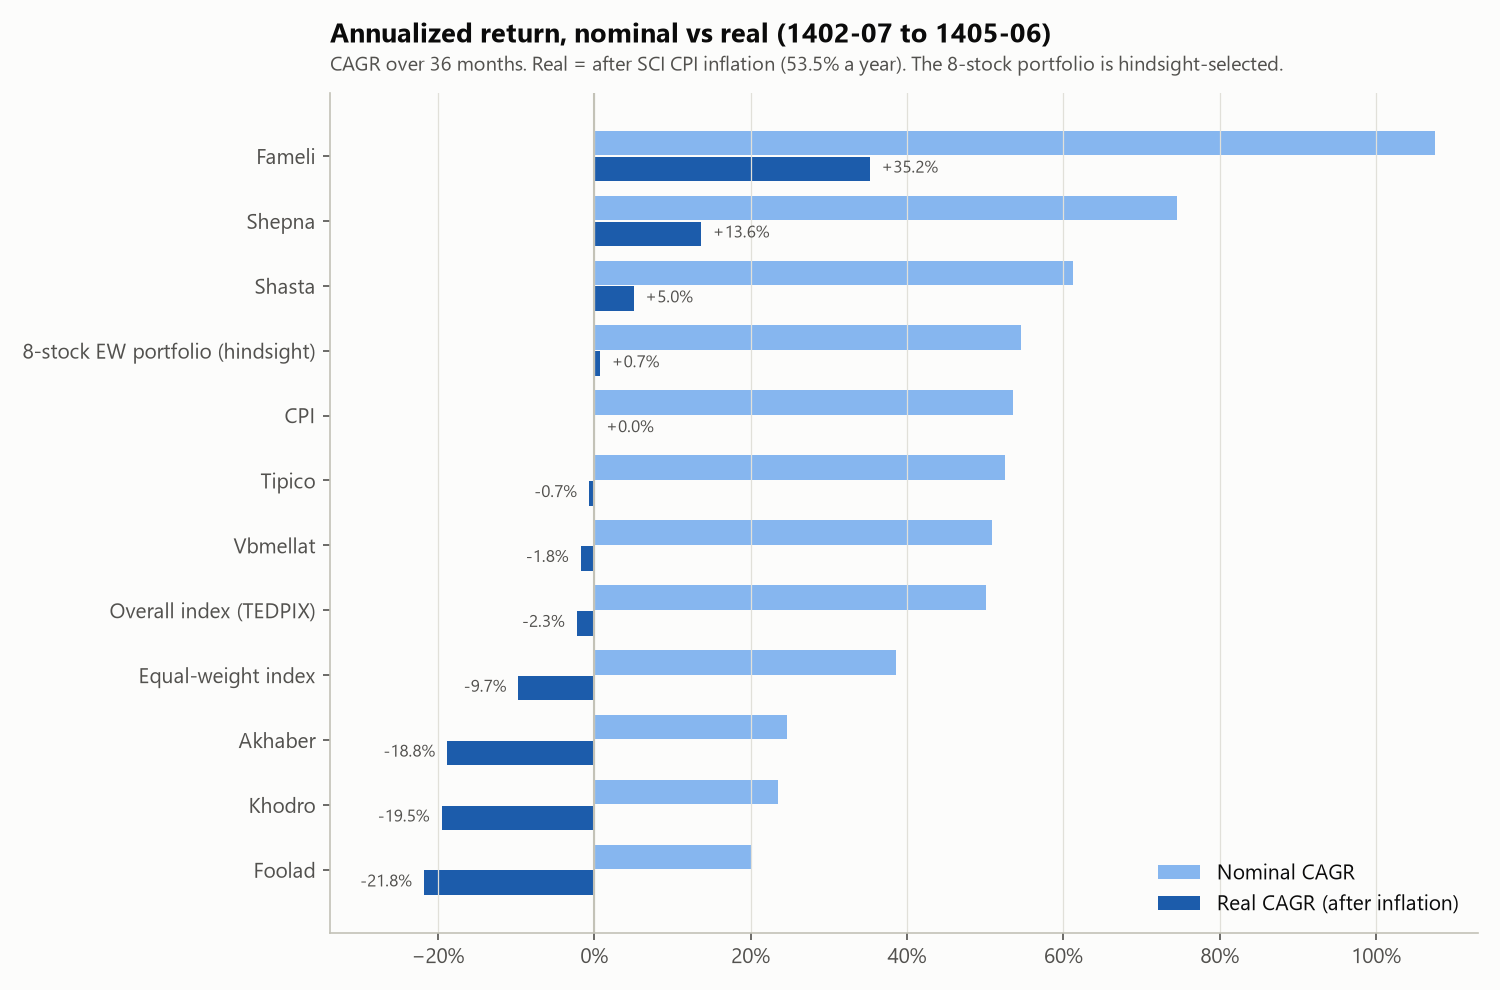

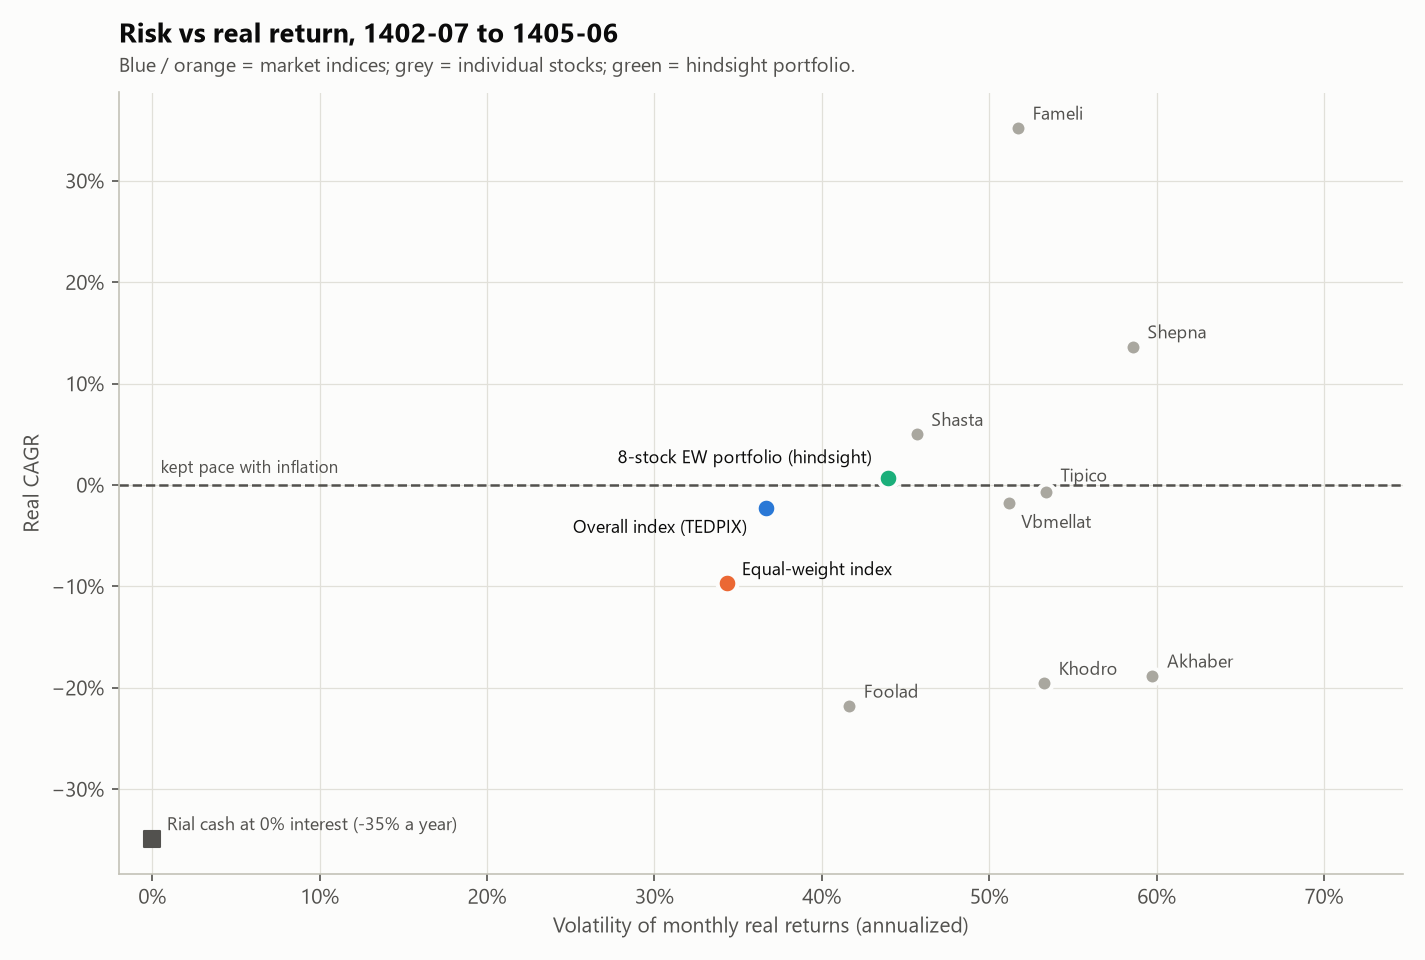

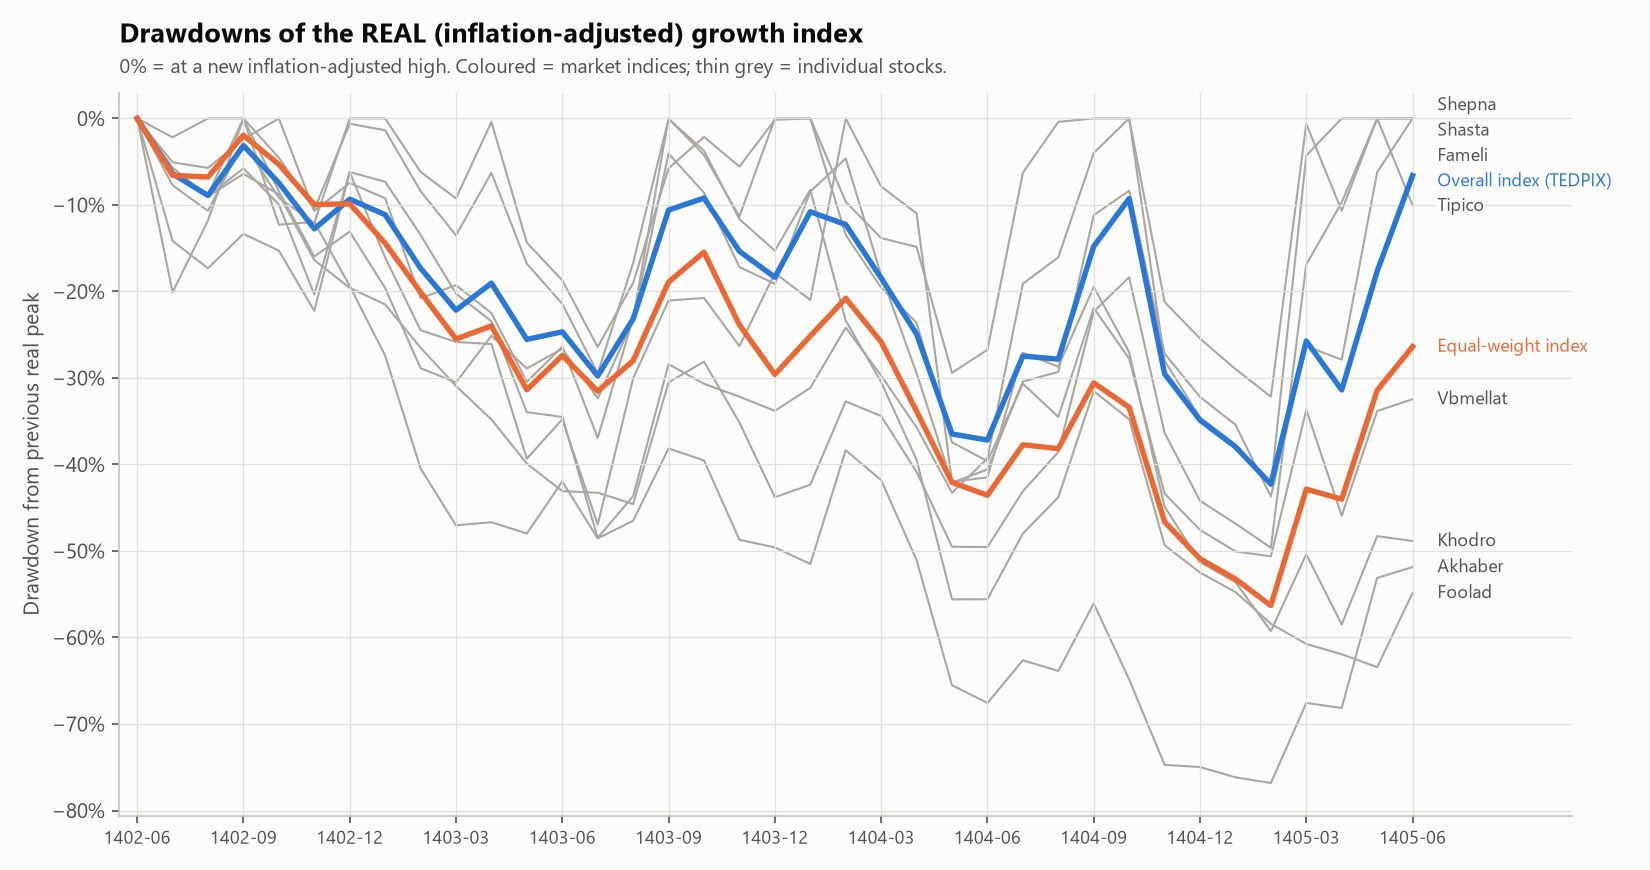

In [3]:
display(Image(FIG / "02_real_vs_nominal_bar.png"))
display(Image(FIG / "03_risk_return_scatter.png"))
display(Image(FIG / "04_drawdowns.png"))

**Reading:** the overall index lost a little to inflation and the equal-weight index lost more,
so the average listed company did worse than the large caps. Rial cash at 0% sits far below
everything. The individual stocks spread out widely in both risk and return.

## 2. Period breakdown: real return per 12-month block (per year)

Each value is the compounded real return over one 12-month block, so it is a return per year.

In [4]:
y = res["yearly"]
blocks = y.pivot(index="series", columns="block", values="real_return_per_year")
order = [an.LABELS[c] for c in an.STOCK_CODES + an.MARKET_CODES + [an.PORTFOLIO_CODE, "cpi"]]
blocks = blocks.loc[order]
display(blocks.map(lambda v: f"{v:+.1%}"))
print("Real return per year, by 12-month block (above)")
print("Rank among the 8 stocks (1 = best real return in the block):")
display(res["ranks"])
print("Rank stability (Spearman correlation of stock ranks):")
display(res["rank_stability"].round(2))

block,1402-07..1403-06,1403-07..1404-06,1404-07..1405-06
series,,,
Foolad,-16.8%,-43.5%,+1.6%
Fameli,-13.0%,-7.3%,+206.5%
Shepna,-34.5%,-7.3%,+141.8%
Khodro,-34.8%,-8.7%,-12.6%
Vbmellat,-26.3%,+15.0%,+11.9%
Akhaber,-35.5%,-44.1%,+48.5%
Shasta,-22.3%,-19.0%,+84.0%
Tipico,-43.1%,-11.4%,+94.2%
Overall index (TEDPIX),-24.7%,-16.6%,+48.7%


Real return per year, by 12-month block (above)
Rank among the 8 stocks (1 = best real return in the block):


block,1402-07..1403-06,1403-07..1404-06,1404-07..1405-06
series,,,
Akhaber,7,8,5
Fameli,1,2,1
Foolad,2,7,7
Khodro,6,4,8
Shasta,3,6,4
Shepna,5,3,2
Tipico,8,5,3
Vbmellat,4,1,6


Rank stability (Spearman correlation of stock ranks):


,from,to,spearman_rank_corr
0,1402-07..1403-06,1403-07..1404-06,0.26
1,1403-07..1404-06,1404-07..1405-06,0.29
2,1402-07..1403-06,1404-07..1405-06,0.14


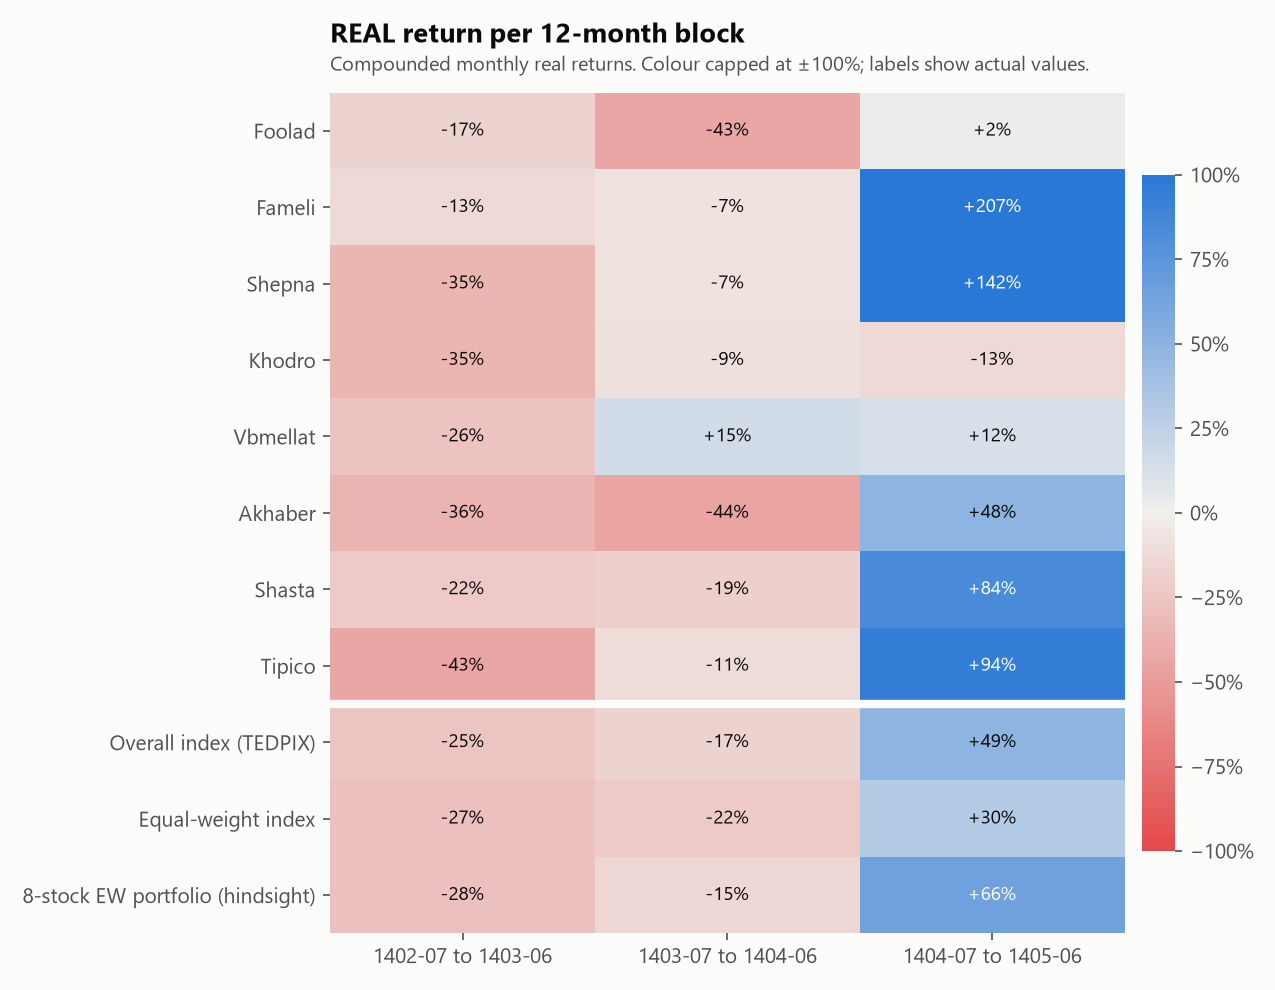

In [5]:
display(Image(FIG / "05_yearly_real_returns_heatmap.png"))

**Did the ranking change?** Yes. Rank correlations between consecutive years are low,
and only Fameli stayed near the top in every block. Every series lost to inflation in the first
block, and all but Vbmellat lost again in the second. The whole real gain of the market came in
1404-07 to 1405-06.

## 3. Market closure (1404-12-09 to 1405-02-28)

The overall index was flat and at zero volume on 50 index days. Nothing could be bought or
sold. All figures in this section are **cumulative over the stated window**, not annualized.

* **Primary (pro-rated):** CPI is interpolated geometrically by calendar day within each month
  (the monthly CPI is taken as the end-of-month level), giving CPI on the exact date of the last
  close before the closure (1404-12-06) and of the first close after it (1405-02-29). The
  20-trading-day row uses CPI on that 20th trading day.
* **Sensitivity (whole months):** CPI from the end of 1404-11 to the end of 1405-02, three full
  months although the closure lasted about 2.6. The 20-trading-day row uses CPI to the end of
  1405-03.

In [6]:
c = res["closure"]
print(f"Closed index days: {c['closed_days']}  ({c['first_closed']} to {c['last_closed']})")
print(f"Last close before: {c['last_open_before']}   first close after: {c['reopen']}")
print(f"CPI change, pro-rated {c['last_open_before']} to {c['reopen']}: {c['cpi_change_prorated']:+.1%} (cumulative)")
print(f"CPI change, whole months {c['cpi_from']} to {c['cpi_to']}: {c['cpi_change_monthly']:+.1%} (cumulative)")
cols = ["nominal_change_reopen", "cpi_change_reopen_prorated", "real_change_reopen_prorated",
        "cpi_change_reopen_monthly", "real_change_reopen_monthly",
        "nominal_change_20d", "cpi_change_20d_prorated", "real_change_20d_prorated",
        "cpi_change_20d_monthly", "real_change_20d_monthly"]
t = c["table"][["series", "type", "last_close_before", "first_close_after",
                "close_after_20_trading_days"] + cols + ["note"]]
pct(t, cols).fillna("")

Closed index days: 50  (1404-12-09 to 1405-02-28)
Last close before: 1404-12-06   first close after: 1405-02-29
CPI change, pro-rated 1404-12-06 to 1405-02-29: +18.6% (cumulative)
CPI change, whole months 1404-11 to 1405-02: +20.6% (cumulative)


,series,type,last_close_before,first_close_after,close_after_20_trading_days,nominal_change_reopen,cpi_change_reopen_prorated,real_change_reopen_prorated,cpi_change_reopen_monthly,real_change_reopen_monthly,nominal_change_20d,cpi_change_20d_prorated,real_change_20d_prorated,cpi_change_20d_monthly,real_change_20d_monthly,note
0,Overall index (TEDPIX),market_index,1404-12-06,1405-02-29,1405-03-26,+0.1%,+18.6%,-15.6%,+20.6%,-17.0%,+37.3%,+25.2%,+9.7%,+27.8%,+7.5%,
1,Equal-weight index,market_index,1404-12-06,1405-02-29,1405-03-26,+0.3%,+18.6%,-15.5%,+20.6%,-16.9%,+41.9%,+25.2%,+13.4%,+27.8%,+11.0%,
2,Foolad,stock,1404-12-06,1405-05-17,1405-06-15,-8.5%,+32.7%,,+36.3%,,+3.7%,+37.5%,,+42.1%,,symbol not trading at the closure edges (1404-...
3,Fameli,stock,1404-12-06,1405-02-29,1405-03-26,+0.9%,+18.6%,-14.9%,+20.6%,-16.3%,+64.4%,+25.2%,+31.3%,+27.8%,+28.7%,
4,Shepna,stock,1404-12-06,1405-02-29,1405-03-26,-2.3%,+18.6%,-17.7%,+20.6%,-19.0%,+63.1%,+25.2%,+30.3%,+27.8%,+27.6%,
5,Khodro,stock,1404-12-06,1405-02-29,1405-03-26,-2.8%,+18.6%,-18.0%,+20.6%,-19.4%,+21.8%,+25.2%,-2.7%,+27.8%,-4.7%,
6,Vbmellat,stock,1404-12-06,1405-02-29,1405-03-26,+5.2%,+18.6%,-11.4%,+20.6%,-12.8%,+60.3%,+25.2%,+28.0%,+27.8%,+25.4%,
7,Akhaber,stock,1404-12-06,1405-02-29,1405-03-26,+2.8%,+18.6%,-13.3%,+20.6%,-14.8%,+50.0%,+25.2%,+19.8%,+27.8%,+17.4%,
8,Shasta,stock,1404-12-06,1405-02-29,1405-03-26,-2.9%,+18.6%,-18.2%,+20.6%,-19.5%,+22.2%,+25.2%,-2.4%,+27.8%,-4.4%,
9,Tipico,stock,1404-12-06,1405-02-29,1405-03-30,+0.1%,+18.6%,-15.6%,+20.6%,-17.0%,+75.2%,+26.1%,+38.9%,+27.8%,+37.1%,


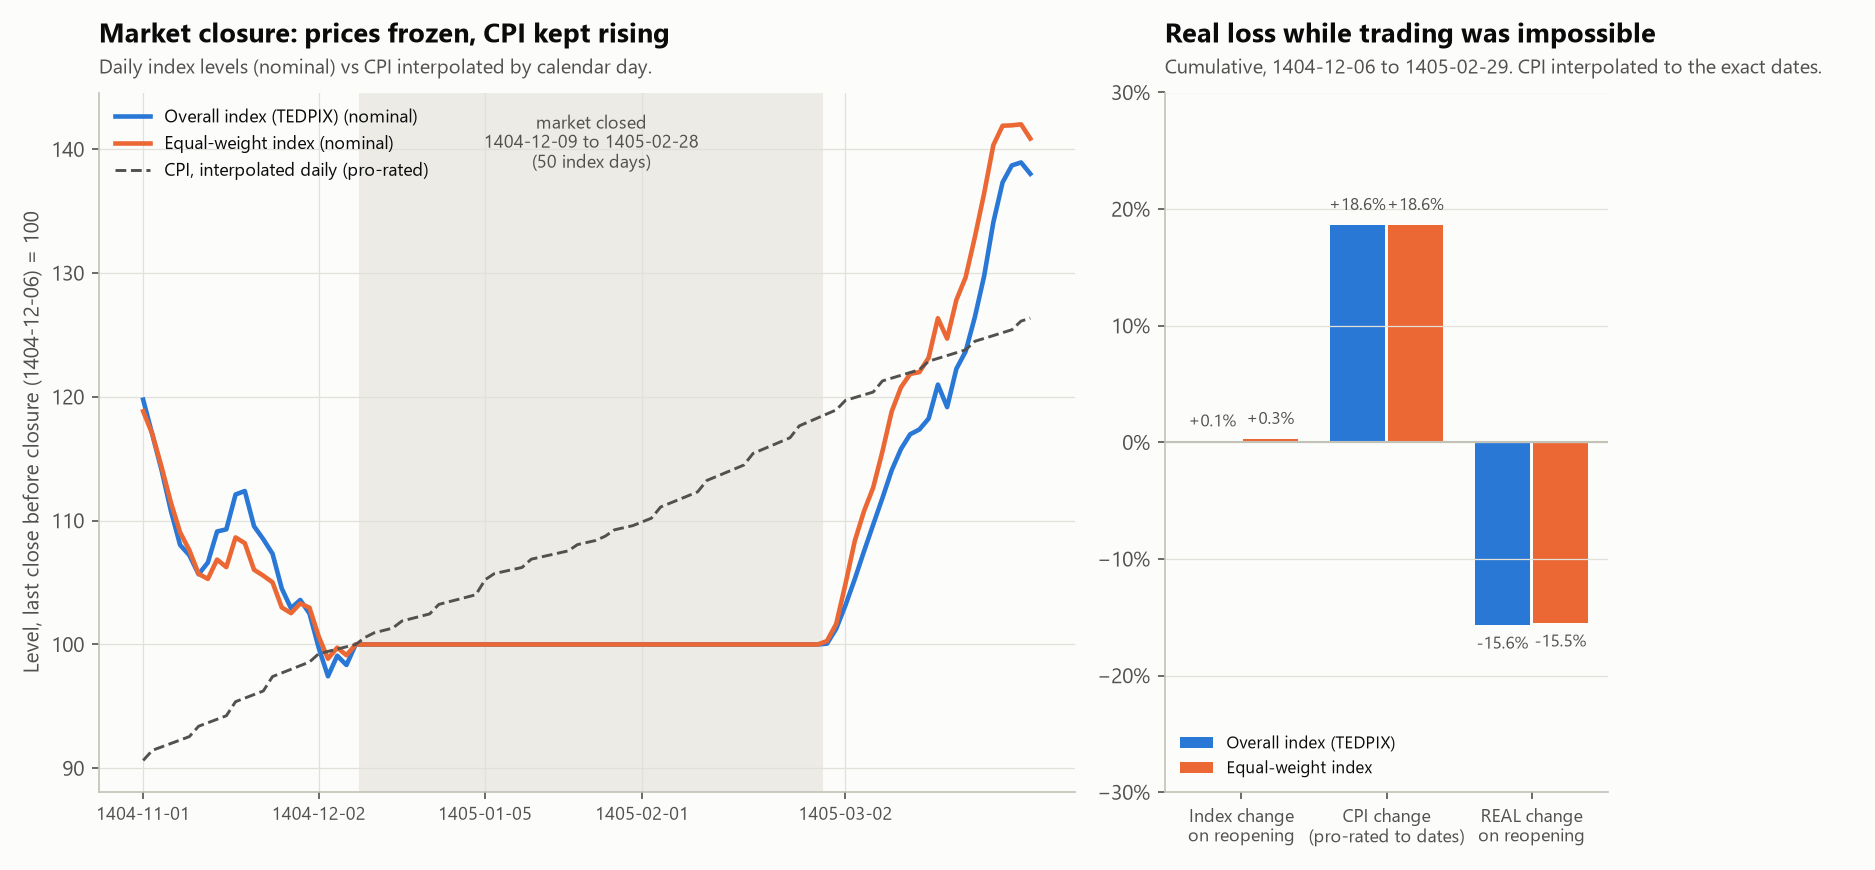

In [7]:
display(Image(FIG / "08_closure_period.png"))

**Reading:** on reopening, both market indices were where they had been 50 trading days
earlier, while consumer prices had kept rising (table above). That is the real loss investors
carried while they could not trade. The market then caught up over the following weeks. That
gradual pace is consistent with TSE daily price limits, although this data cannot prove the cause. Foolad stayed suspended until 1405-05-17, so its row is
not comparable.

## 4. Equal-weight portfolio of the 8 stocks (HINDSIGHT-SELECTED)

Equal weights, rebalanced monthly: each month's return is the average of the 8 stocks' returns.
**The 8 stocks were chosen after the period, so this is not an investable strategy and not
evidence about the market.** It only shows what diversifying across these sectors would have
done.

`real_cagr` is per year; `real_cum_3y` is cumulative over 3 years.

In [8]:
p = res["risk"].set_index("code").loc[[an.PORTFOLIO_CODE, "index_total", "index_equal_weight"]]
pct(p[["series", "nominal_cagr", "real_cagr", "real_cum_3y", "real_max_drawdown_peak_to_trough"]],
    ["nominal_cagr", "real_cagr", "real_cum_3y", "real_max_drawdown_peak_to_trough"])

,series,nominal_cagr,real_cagr,real_cum_3y,real_max_drawdown_peak_to_trough
code,,,,,
ew_portfolio_8,8-stock EW portfolio (hindsight),+54.6%,+0.7%,+2.2%,-41.2%
index_total,Overall index (TEDPIX),+50.1%,-2.3%,-6.6%,-42.3%
index_equal_weight,Equal-weight index,+38.6%,-9.7%,-26.4%,-56.3%


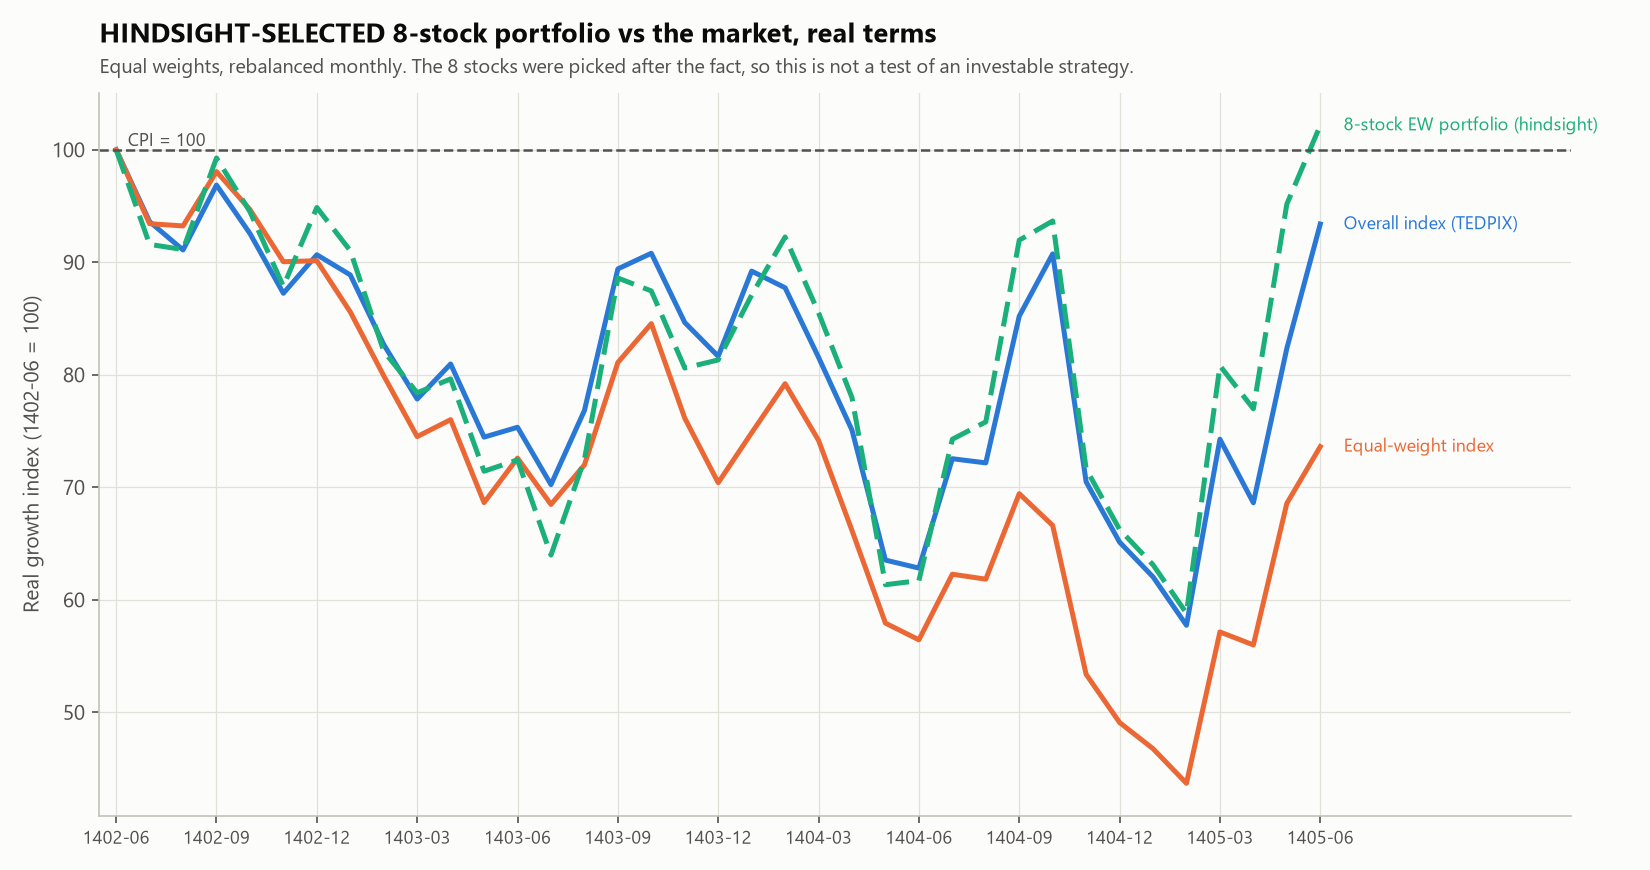

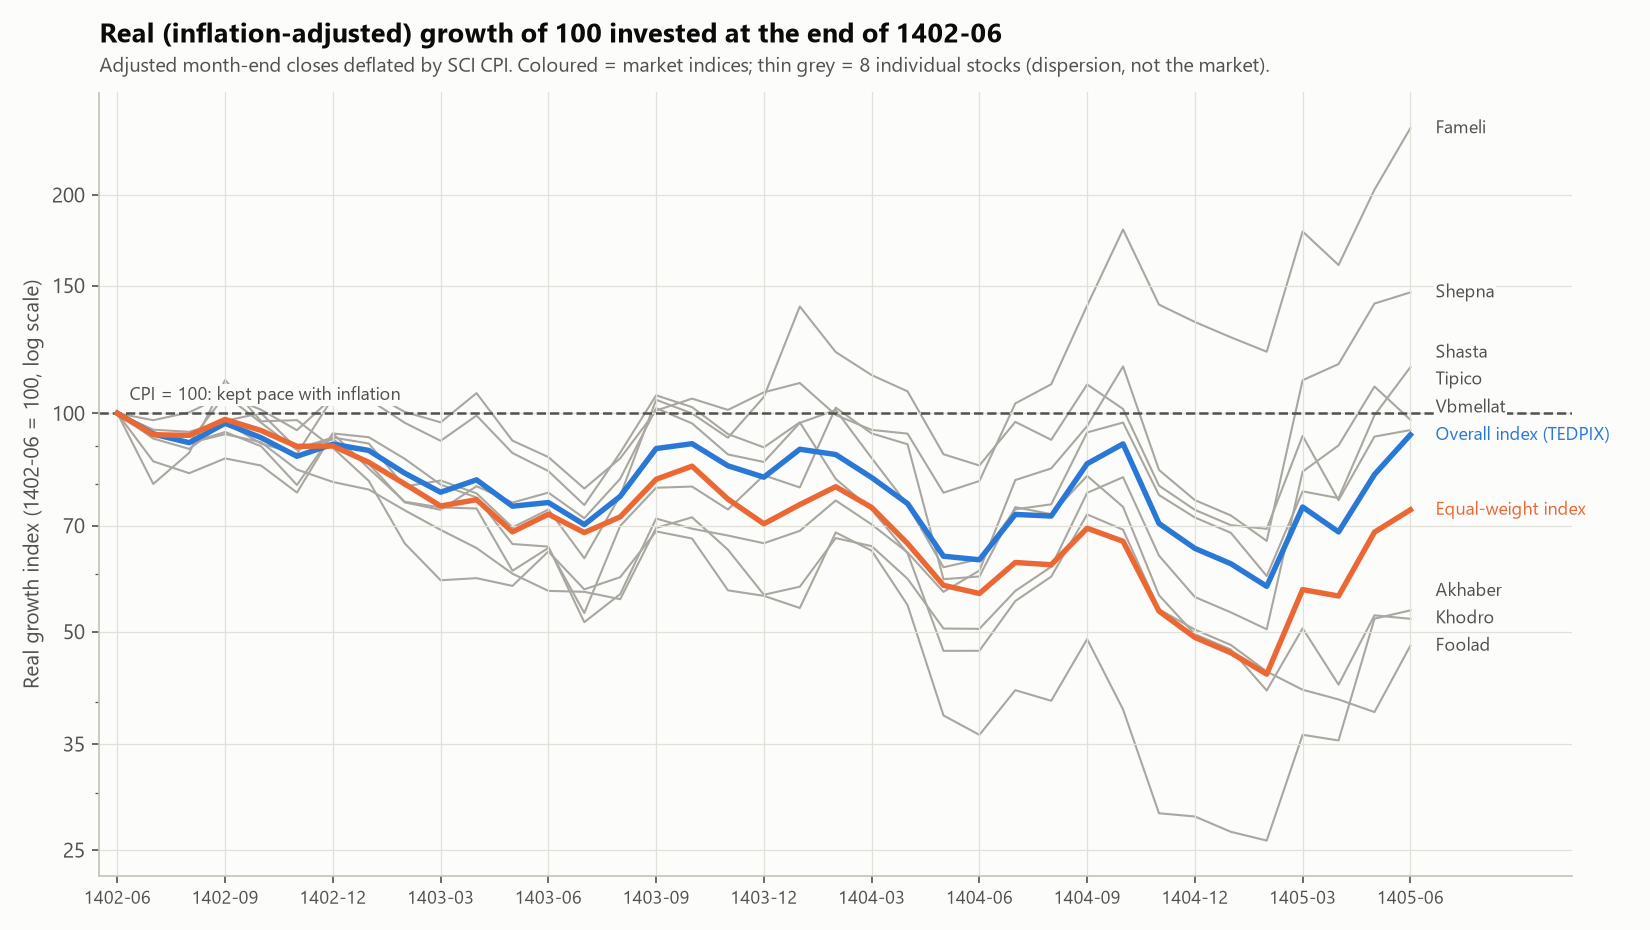

In [9]:
display(Image(FIG / "09_hindsight_portfolio.png"))
display(Image(FIG / "01_cumulative_real_growth.png"))

## 5. Correlation of monthly real returns

,Foolad,Fameli,Shepna,Khodro,Vbmellat,Akhaber,Shasta,Tipico,Overall index (TEDPIX)
Foolad,1.00,0.64,0.46,0.55,0.61,0.41,0.69,0.30,0.70
Fameli,0.64,1.00,0.87,0.67,0.71,0.60,0.83,0.71,0.92
Shepna,0.46,0.87,1.00,0.70,0.70,0.66,0.81,0.87,0.86
Khodro,0.55,0.67,0.70,1.00,0.68,0.74,0.74,0.57,0.74
Vbmellat,0.61,0.71,0.70,0.68,1.00,0.61,0.81,0.61,0.83
Akhaber,0.41,0.60,0.66,0.74,0.61,1.00,0.79,0.73,0.76
Shasta,0.69,0.83,0.81,0.74,0.81,0.79,1.00,0.76,0.95
Tipico,0.30,0.71,0.87,0.57,0.61,0.73,0.76,1.00,0.78
Overall index (TEDPIX),0.70,0.92,0.86,0.74,0.83,0.76,0.95,0.78,1.00


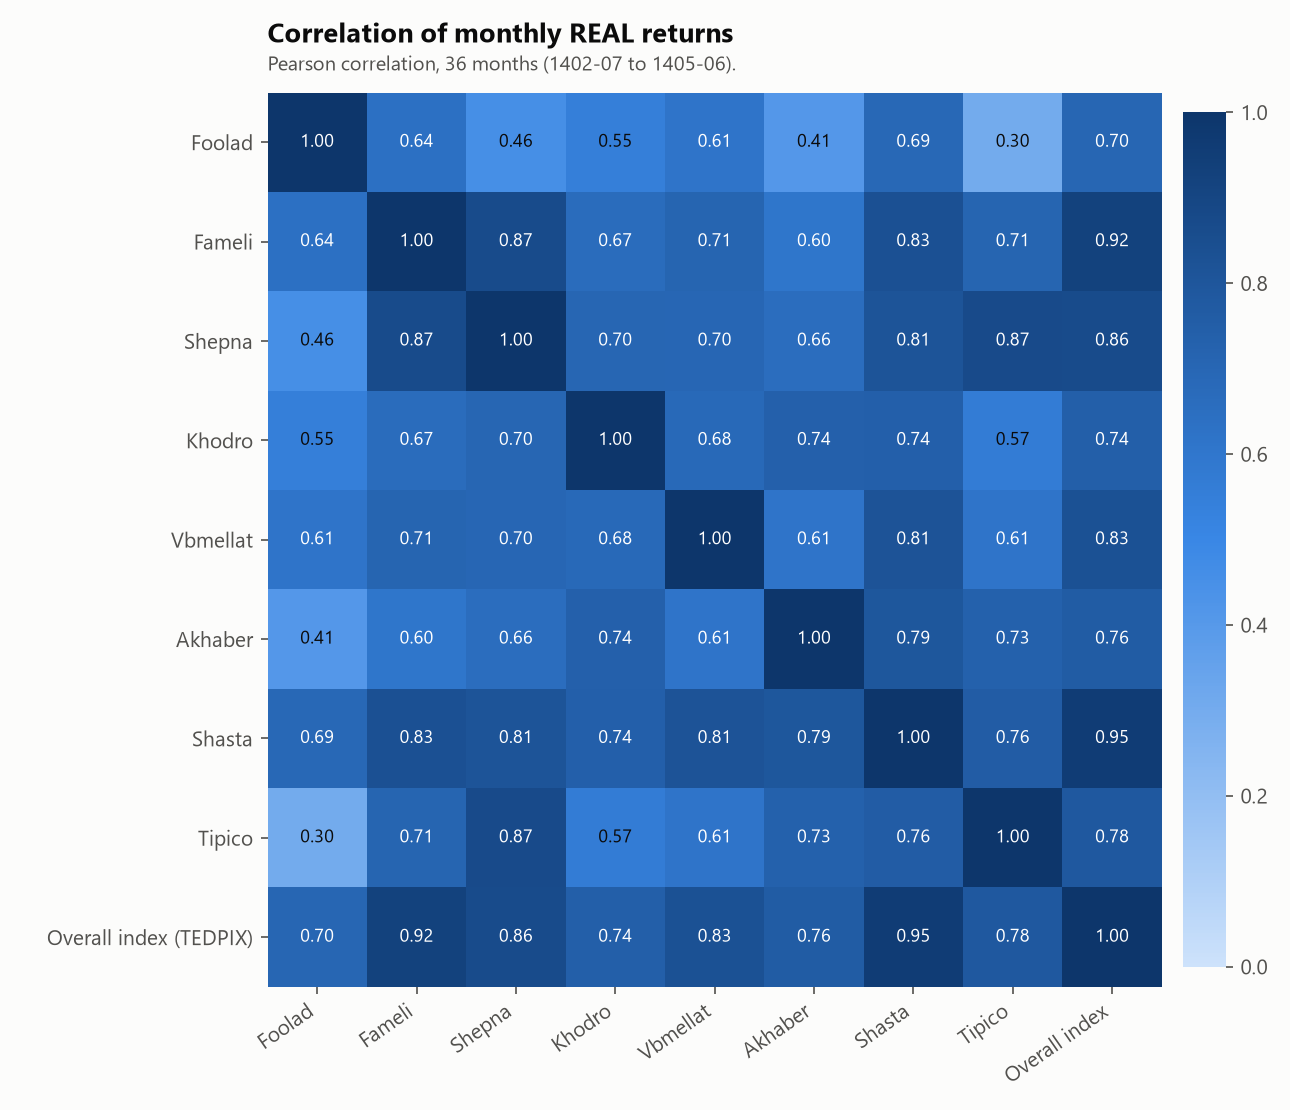

In [10]:
display(res["corr"].round(2))
display(Image(FIG / "06_correlation_heatmap.png"))

**Reading:** all stocks move strongly with the market. The correlation with the overall
index is 0.70 to 0.95, which limits how much diversifying across these 8 names reduces risk.
Foolad and Tipico are the least correlated pair.

## 6. Rolling 12-month real return of the market indices

Each value is the real return over the 12 months ending that month, so it is a return per year.

month_jalali,1403-06,1403-07,1403-08,1403-09,1403-10,1403-11,1403-12,1404-01,1404-02,1404-03,1404-04,1404-05,1404-06,1404-07,1404-08,1404-09,1404-10,1404-11,1404-12,1405-01,1405-02,1405-03,1405-04,1405-05,1405-06
code,,,,,,,,,,,,,,,,,,,,,,,,,
index_total,-24.7%,-25.0%,-15.7%,-7.7%,-1.9%,-3.0%,-10.0%,+0.4%,+6.1%,+4.8%,-7.3%,-14.7%,-16.6%,+3.3%,-6.1%,-4.7%,-0.1%,-16.7%,-20.2%,-30.5%,-34.2%,-8.9%,-8.6%,+29.6%,+48.7%
index_equal_weight,-27.4%,-26.7%,-22.8%,-17.3%,-10.7%,-15.4%,-21.9%,-12.5%,-0.9%,-0.5%,-13.0%,-15.6%,-22.2%,-9.1%,-14.1%,-14.4%,-21.2%,-29.9%,-30.3%,-37.5%,-44.8%,-23.0%,-15.4%,+18.4%,+30.4%


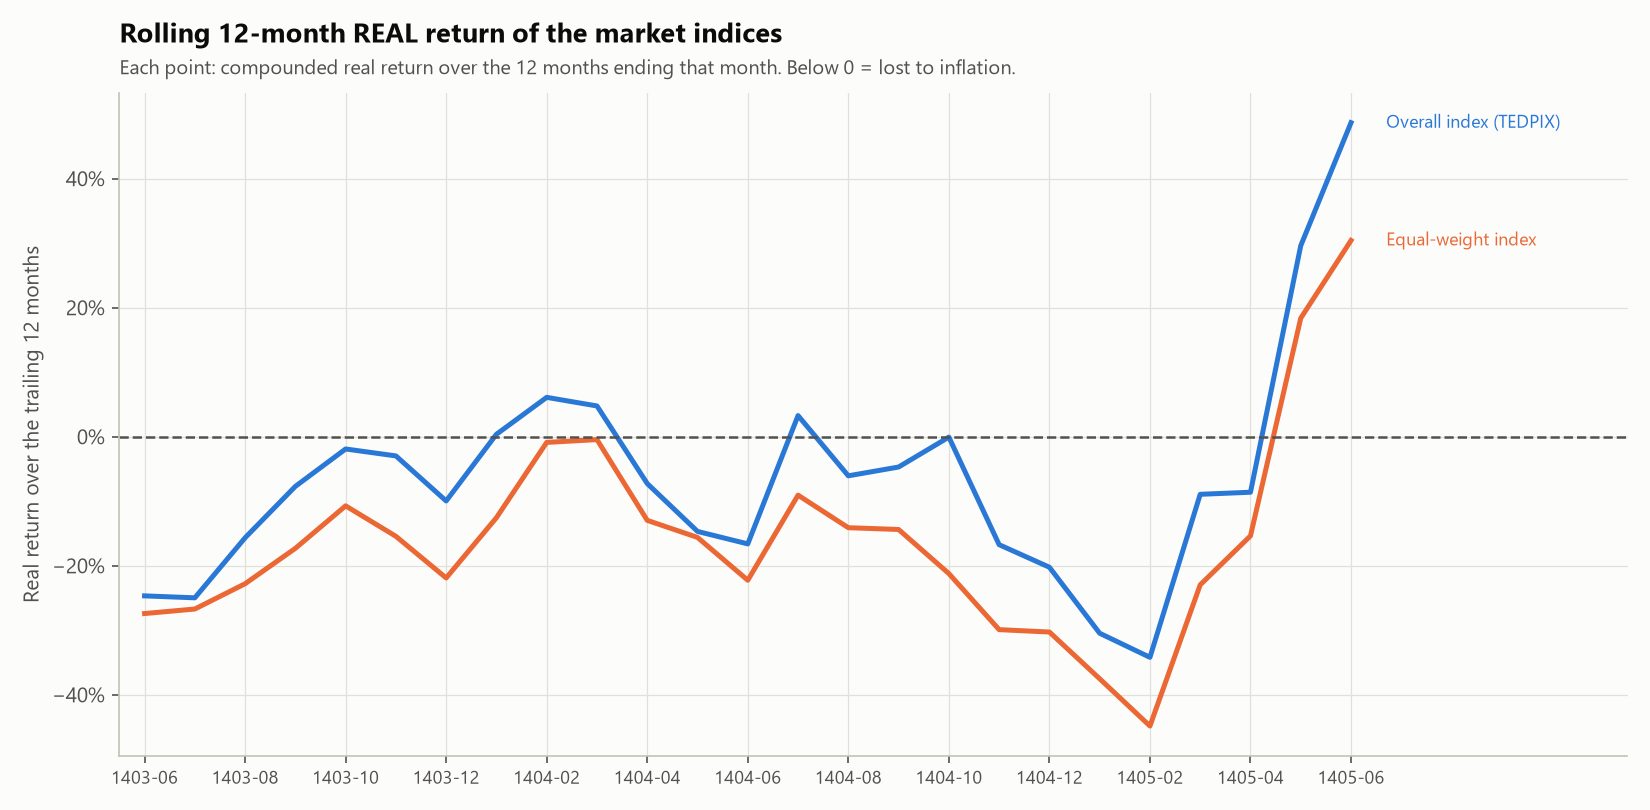

In [11]:
display(res["rolling"].map(lambda v: f"{v:+.1%}").T)
display(Image(FIG / "07_rolling_12m_real.png"))

## 7. Risk-free context

TSETMC treasury bills (اخزا) are **not listed** on the IFB YTM page that algotik-tse reads.
The closest government instrument there is **government Murabaha bonds (اراد)**, so those are
used instead. The yield to maturity is a forward-looking snapshot; the inflation figures are
trailing (the 12 months to 1405-06). The comparison therefore asks what the yield implies *if*
inflation stays at last year's level.

In [12]:
rf = res["risk_free"]
if rf is None:
    print("No IFB snapshot found: item skipped.")
else:
    display(Markdown(
        f"If inflation stays at last year's level, today's government bond yield implies a real "
        f"return of about {rf['real_ytm_vs_avg12']:.0%} per year "
        f"({rf['real_ytm_vs_p2p']:.0%} per year against point-to-point inflation).\n\n"
        f"Median YTM of اراد bonds: {rf['ytm_median']:.1%} per year ({rf['n_bonds']} issues traded "
        f"in the 30 days before the snapshot). Source: {rf['source']}, snapshot "
        f"{rf['snapshot_jalali']} (`{rf['file']}`). Trailing inflation, 12 months to "
        f"{rf['cpi_month']}: {rf['inflation_12m_average']:.1%} per year (12-month average), "
        f"{rf['inflation_point_to_point']:.1%} point-to-point."))
    display(pd.Series(rf))

If inflation stays at last year's level, today's government bond yield implies a real return of about -19% per year (-26% per year against point-to-point inflation).

Median YTM of اراد bonds: 40.4% per year (103 issues traded in the 30 days before the snapshot). Source: https://ifb.ir/ytm.aspx, snapshot 1405-07-22 (`data/external/ifb_debt_yields_14050722.csv`). Trailing inflation, 12 months to 1405-06: 73.6% per year (12-month average), 89.8% point-to-point.

file                        data/external/ifb_debt_yields_14050722.csv
source                                         https://ifb.ir/ytm.aspx
snapshot_date_gregorian                                     2026-10-14
snapshot_jalali                                             1405-07-22
instrument                            government Murabaha bonds (اراد)
n_bonds                                                            103
ytm_median                                                      0.4042
ytm_min                                                         0.2719
ytm_max                                                         0.4346
cpi_month                                                      1405-06
inflation_point_to_point                                      0.897859
inflation_12m_average                                          0.73581
real_ytm_vs_p2p                                              -0.260114
real_ytm_vs_avg12                                            -0.191041
dtype:

## Data caveats

* Adjusted prices treat rights issues paid in cash like bonus shares, which slightly overstates
  returns around those events.
* In a month with no trade, the previous price is carried forward. The move then lands in the
  month trading resumes. Such months are flagged (`flagged_months`).
* CPI is a monthly average of prices collected from the 1st to the 28th. Stock returns are
  end-of-month to end-of-month, so single-month real returns contain some timing noise. Over
  36 months this noise largely cancels.
* Five days of the petroleum sector index were corrected (decimal shift). That index is not
  used in any finding. See `reports/corrections.md`.

## Key findings

In [13]:
display(Markdown("\n\n".join(res["findings"])))

**1. The market did not beat inflation, but it beat cash by a wide margin.** CPI rose 262% cumulative over 3 years (53.5% per year). In real terms the overall index lost 6.6% cumulative over 3 years (-2.3% per year) and the equal-weight index lost 26.4% cumulative over 3 years (-9.7% per year). Rial cash at 0% lost 72% of its purchasing power, cumulative over 3 years. *Implication:* idle rial cash was by far the costliest place to hold money; a broad index nearly preserved value, at the price of 37% real volatility per year.

**2. Single stocks are bets, not inflation hedges.** 3 of the 8 stocks beat inflation (Fameli +147%, Shepna +47%, Shasta +16% real, cumulative over 3 years). Real CAGRs ranged from -21.8% per year (Foolad) to +35.2% per year (Fameli). Even this hindsight-selected set, held in equal weights and rebalanced monthly, made only +2.2% real cumulative over 3 years, which is +0.7% per year. *Implication:* the spread between stocks dwarfs the gap between the market and inflation; protection against inflation needs diversification, not a favourite ticker.

**3. All of the real gain came in the last 12 months, and leadership kept changing.** The overall index returned -24.7%, -16.6% and +48.7% real per year in the three 12-month blocks. The rank correlation of the 8 stocks between consecutive years was only 0.26 and 0.29. *Implication:* beating inflation with equities needed a multi-year horizon and the stomach for two losing years; last year's winner was a weak guide to next year's.

**4. Liquidity risk is real: the 50-trading-day market closure cost 15.6% in real terms by reopening.** From the last close (1404-12-06) to the first close after the closure (1405-02-29) the overall index changed +0.1% nominal while CPI, pro-rated to those dates, rose 18.6%; all three figures are cumulative over the closure. Using whole CPI months (1404-11 to 1405-02) instead gives -17.0%. Twenty trading days after reopening the index was +37.3% nominal and +9.7% real, cumulative from the last close before the closure (+7.5% with whole CPI months). *Implication:* listed equities can be locked for months; a treasury must keep its operating runway in instruments it can actually withdraw.

**5. The 'safe' asset is negative in real terms too.** If inflation stays at last year's level, today's government bond yield implies a real return of about -19% per year (-26% per year against point-to-point inflation). The median yield to maturity of government Murabaha bonds (اراد, 103 issues traded in the 30 days before the snapshot) was 40.4% per year (IFB snapshot 1405-07-22, https://ifb.ir/ytm.aspx); this yield is forward-looking. Last year's inflation is trailing: 73.6% per year as a 12-month average and 89.8% point-to-point (12 months to 1405-06). *Implication:* fixed rial income only slows the loss; size rial holdings to near-term rial costs and treat the rest as capital to protect, not to park.